In [27]:
%pip install pandas numpy
%pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries are working!")


All libraries are working!


In [29]:
df = pd.read_csv(r"C:\Users\SHRUTI\Downloads\data-export (1).csv")

df.head()

,# ----------------------------------------,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,Session primary channel group (Default channel...,Date + hour (YYYYMMDDHH),Users,Sessions,Engaged sessions,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count
1,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
2,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
3,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
4,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044


In [30]:
df.columns =df.iloc[0]
df = df.drop(index =0).reset_index(drop =True)
df.columns =["channel group","Datehour","Users","Sessions","Engaged session","Average engagement time per session","Engaged sessions per user","Events per session","Engagement rate","Event count"]

In [31]:
df.head()

,channel group,Datehour,Users,Sessions,Engaged session,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count
0,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
1,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
2,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
3,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044
4,Organic Social,2024041720,175,221,112,46.918552036199100,0.64,4.529411764705880,0.5067873303167420,1001


In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3182 entries, 0 to 3181
Data columns (total 10 columns):
 #   Column                               Non-Null Count  Dtype
---  ------                               --------------  -----
 0   channel group                        3182 non-null   str  
 1   Datehour                             3182 non-null   str  
 2   Users                                3182 non-null   str  
 3   Sessions                             3182 non-null   str  
 4   Engaged session                      3182 non-null   str  
 5   Average engagement time per session  3182 non-null   str  
 6   Engaged sessions per user            3182 non-null   str  
 7   Events per session                   3182 non-null   str  
 8   Engagement rate                      3182 non-null   str  
 9   Event count                          3182 non-null   str  
dtypes: str(10)
memory usage: 248.7 KB


In [33]:
df["DateHour"] = pd.to_datetime(df["DateHour"], format="%Y%m%d%H", errors='coerce')



KeyError: 'DateHour'

In [ ]:
df["DateHour"] = pd.to_datetime(df["DateHour"], format="%Y%m%d%H", errors='coerce')

In [ ]:
df["DateHour"] = pd.to_datetime(df["DateHour"],format="%Y%m%d%H", errors= 'coerce')

In [ ]:
print(df.columns.tolist())

In [ ]:
# Remove extra spaces from column names
df.columns = df.columns.astype(str).str.strip()

# Rename the date column to DateHour
df.rename(
    columns=lambda c: "DateHour"
    if "date" in c.lower() and "hour" in c.lower()
    else c,
    inplace=True
)

# Convert date and hour
df["DateHour"] = pd.to_datetime(
    df["DateHour"].astype(str).str.replace(r"\.0$", "", regex=True),
    format="%Y%m%d%H",
    errors="coerce"
)

# Convert numeric columns
numeric_cols = df.select_dtypes(exclude=["object", "datetime"]).columns
df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)

# Extract hour
df["Hour"] = df["DateHour"].dt.hour

display(df.head())

In [ ]:
df.info()

In [ ]:

numeric_cols = df.columns.drop(["Channel Group", "DateHour"])

df[numeric_cols] = df[numeric_cols].apply(pd.to_numeric, errors='coerce')

df["Hour"] = df["DateHour"].dt.hour

In [ ]:
# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Find the date column
date_col = next(
    (c for c in df.columns
     if "date" in c.lower() and "hour" in c.lower()),
    None
)

# Find the channel column
channel_col = next(
    (c for c in df.columns
     if "channel" in c.lower() and "group" in c.lower()),
    None
)

# Exclude date and channel columns
exclude_cols = [c for c in [date_col, channel_col] if c is not None]
numeric_cols = df.columns.drop(exclude_cols)

# Convert remaining columns to numeric values
df[numeric_cols] = df[numeric_cols].apply(
    pd.to_numeric, errors="coerce"
)

print("Data cleaning completed!")
display(df.head())

In [ ]:
df.info()


In [ ]:
df.describe()

# session and user over time
sns.set(style="whitegrid")

In [ ]:
plt.figure(figsize=(10,5))
df.groupby("DateHour")[["sessions","users"]].sum().plot(ax=plt.gca())
plt.show()

In [ ]:
import matplotlib.pyplot as plt

# Remove extra spaces from column names
df.columns = df.columns.astype(str).str.strip()

# Find the correct column names automatically
date_col = next(c for c in df.columns if "date" in c.lower() and "hour" in c.lower())
sessions_col = next(c for c in df.columns if c.lower() == "sessions")
users_col = next(c for c in df.columns if c.lower() == "users")

# Create the graph
plt.figure(figsize=(10, 5))

df.groupby(date_col)[[sessions_col, users_col]].sum().plot(
    ax=plt.gca()
)

plt.title("Website Sessions and Users Over Time")
plt.xlabel("Date and Hour")
plt.ylabel("Total Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# total users by channel

channel group
Organic Search    9287878484838282828180808079797878777777767675...
Referral          8584818079797878787776767474747474747372727171...
Unassigned        6544444444433333333333333333333333333222222222...
Direct            2371881581281031021029797939191868686848484838...
Organic Video     2222221111111111111111111111111111111111111111...
Organic Social    2081871751601601521511511501461401401391361351...
Email                                                           110
Name: Users, dtype: str


TypeError: no numeric data to plot

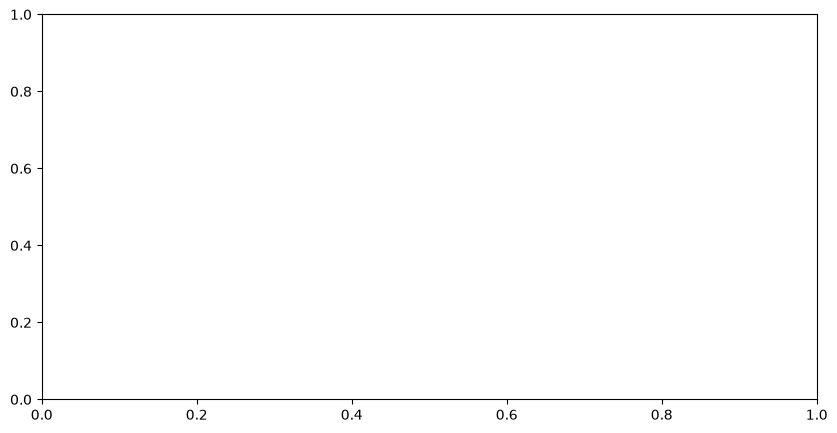

In [34]:
import matplotlib.pyplot as plt

# Find the correct column names
channel_col = next(
    c for c in df.columns
    if "channel" in c.lower() and "group" in c.lower()
)

users_col = next(
    c for c in df.columns
    if c.strip().lower() == "users"
)

# Calculate total users by channel
total_users = df.groupby(channel_col)[users_col].sum().sort_values(
    ascending=False
)

# Display results
print(total_users)

# Create bar chart
total_users.plot(kind="bar", figsize=(10, 5))

plt.title("Total Users by Channel")
plt.xlabel("Channel Group")
plt.ylabel("Total Users")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

,channel group,Total Users
0,Organic Social,47572
1,Direct,30042
2,Organic Search,28387
3,Referral,26774
4,Unassigned,540
5,Organic Video,123
6,Email,2


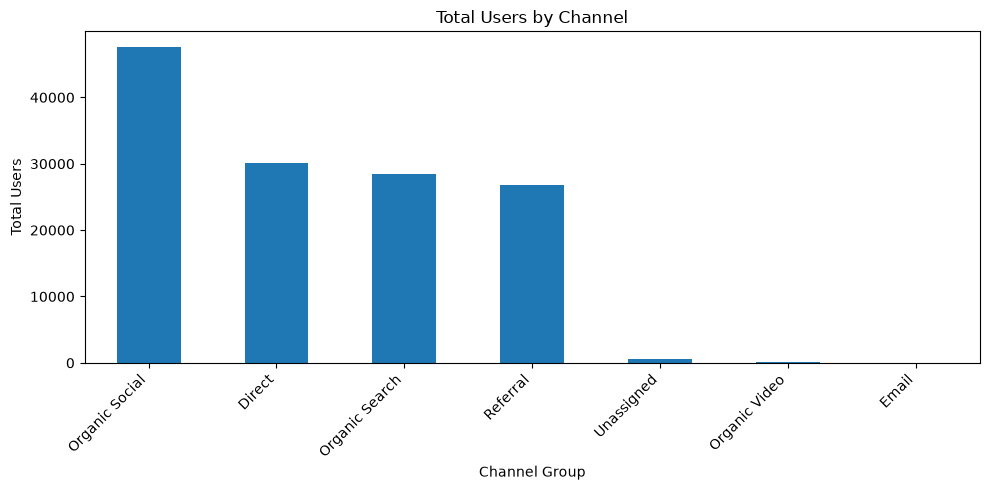

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Find the correct columns
channel_col = next(
    c for c in df.columns
    if "channel" in c.lower() and "group" in c.lower()
)

users_col = next(
    c for c in df.columns
    if c.strip().lower() == "users"
)

# Convert Users to numeric values
df[users_col] = pd.to_numeric(
    df[users_col].astype(str).str.replace(",", ""),
    errors="coerce"
)

# Remove rows with missing channel or user values
clean_df = df.dropna(subset=[channel_col, users_col]).copy()

# Calculate total users by channel
total_users = clean_df.groupby(channel_col)[users_col].sum()
total_users = total_users.sort_values(ascending=False)

# Display results
display(total_users.reset_index(name="Total Users"))

# Create bar chart
plt.figure(figsize=(10, 5))
total_users.plot(kind="bar")

plt.title("Total Users by Channel")
plt.xlabel("Channel Group")
plt.ylabel("Total Users")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [36]:
df.head()


,channel group,Datehour,Users,Sessions,Engaged session,Average engagement time per session,Engaged sessions per user,Events per session,Engagement rate,Event count
0,Direct,2024041623,237,300,144,47.526666666666700,0.6075949367088610,4.673333333333330,0.48,1402
1,Organic Social,2024041719,208,267,132,32.09737827715360,0.6346153846153850,4.295880149812730,0.4943820224719100,1147
2,Direct,2024041723,188,233,115,39.93991416309010,0.6117021276595740,4.587982832618030,0.49356223175965700,1069
3,Organic Social,2024041718,187,256,125,32.16015625,0.6684491978609630,4.078125,0.48828125,1044
4,Organic Social,2024041720,175,221,112,46.918552036199100,0.64,4.529411764705880,0.5067873303167420,1001


#avreage engagement time by channel

,channel group,Average Engagement Time
0,Organic Video,180.360000
1,Referral,92.660842
2,Unassigned,78.957923
3,Email,72.666667
4,Organic Social,53.493681
5,Organic Search,47.005018
6,Direct,45.533104


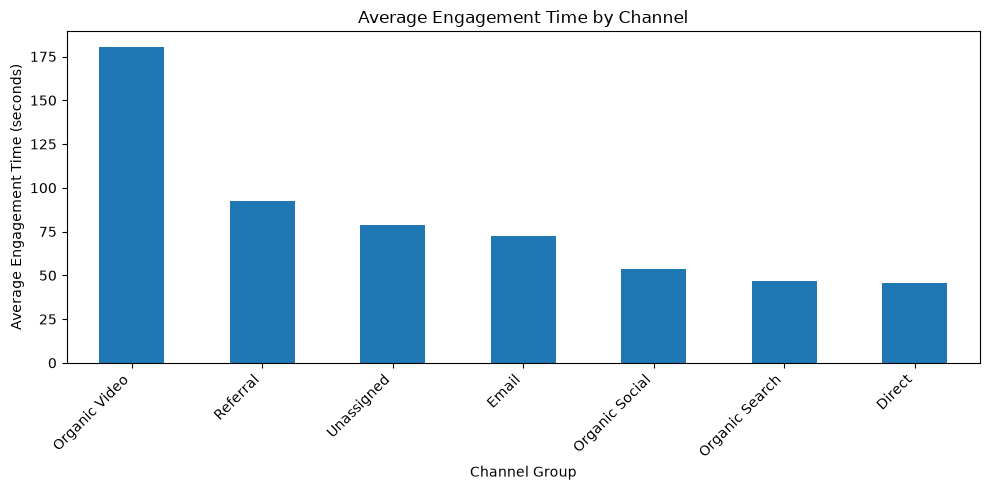

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Find channel and engagement time columns automatically
channel_col = next(
    c for c in df.columns
    if "channel" in c.lower() and "group" in c.lower()
)

engagement_col = next(
    c for c in df.columns
    if "engagement" in c.lower() and "time" in c.lower()
)

# Convert engagement time to numeric
df[engagement_col] = pd.to_numeric(
    df[engagement_col].astype(str).str.replace(",", ""),
    errors="coerce"
)

# Calculate average engagement time by channel
avg_engagement = (
    df.dropna(subset=[channel_col, engagement_col])
      .groupby(channel_col)[engagement_col]
      .mean()
      .sort_values(ascending=False)
)

# Display results
display(avg_engagement.reset_index(name="Average Engagement Time"))

# Create bar chart
plt.figure(figsize=(10, 5))
avg_engagement.plot(kind="bar")

plt.title("Average Engagement Time by Channel")
plt.xlabel("Channel Group")
plt.ylabel("Average Engagement Time (seconds)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#engagement rate distribution by channel

,channel group,Average Engagement Rate
0,Organic Video,0.760000
1,Referral,0.660882
2,Organic Search,0.578906
3,Organic Social,0.541180
4,Direct,0.455723
5,Email,0.333333
6,Unassigned,0.007514


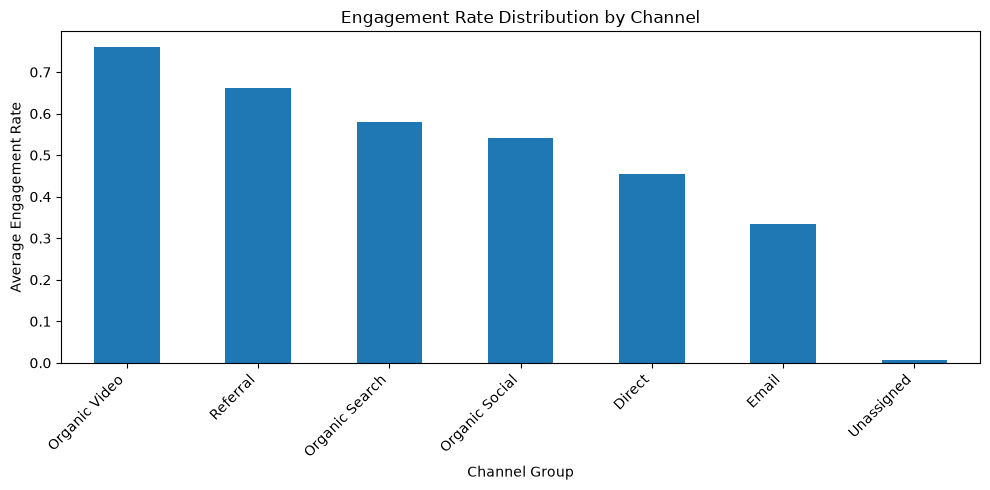

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Find channel and engagement rate columns
channel_col = next(
    c for c in df.columns
    if "channel" in c.lower() and "group" in c.lower()
)

rate_col = next(
    c for c in df.columns
    if "engagement" in c.lower() and "rate" in c.lower()
)

# Convert engagement rate to numeric
df[rate_col] = pd.to_numeric(
    df[rate_col].astype(str).str.replace("%", "").str.replace(",", ""),
    errors="coerce"
)

# Calculate average engagement rate by channel
engagement_distribution = (
    df.dropna(subset=[channel_col, rate_col])
      .groupby(channel_col)[rate_col]
      .mean()
      .sort_values(ascending=False)
)

# Display the table
display(
    engagement_distribution.reset_index(
        name="Average Engagement Rate"
    )
)

# Create bar chart
plt.figure(figsize=(10, 5))
engagement_distribution.plot(kind="bar")

plt.title("Engagement Rate Distribution by Channel")
plt.xlabel("Channel Group")
plt.ylabel("Average Engagement Rate")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

#engaged vs non engaged session

,Session Type,Count
0,Engaged Sessions,90132
1,Non-Engaged Sessions,72763


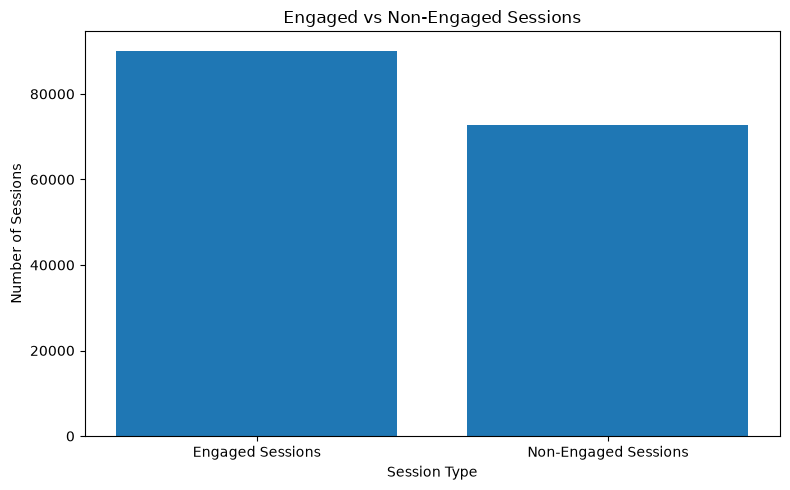

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Find the required columns
session_col = next(
    c for c in df.columns
    if "session" in c.lower() and "engaged" not in c.lower()
)

engaged_col = next(
    c for c in df.columns
    if "engaged" in c.lower() and "session" in c.lower()
)

# Convert values to numeric
df[session_col] = pd.to_numeric(df[session_col], errors="coerce")
df[engaged_col] = pd.to_numeric(df[engaged_col], errors="coerce")

# Calculate total sessions
total_sessions = df[session_col].sum()
engaged_sessions = df[engaged_col].sum()

# Calculate non-engaged sessions
non_engaged_sessions = total_sessions - engaged_sessions

# Create comparison table
comparison = pd.DataFrame({
    "Session Type": ["Engaged Sessions", "Non-Engaged Sessions"],
    "Count": [engaged_sessions, non_engaged_sessions]
})

display(comparison)

# Create bar chart
plt.figure(figsize=(8, 5))
plt.bar(comparison["Session Type"], comparison["Count"])

plt.title("Engaged vs Non-Engaged Sessions")
plt.xlabel("Session Type")
plt.ylabel("Number of Sessions")
plt.tight_layout()
plt.show()

#traffic by hour and channel

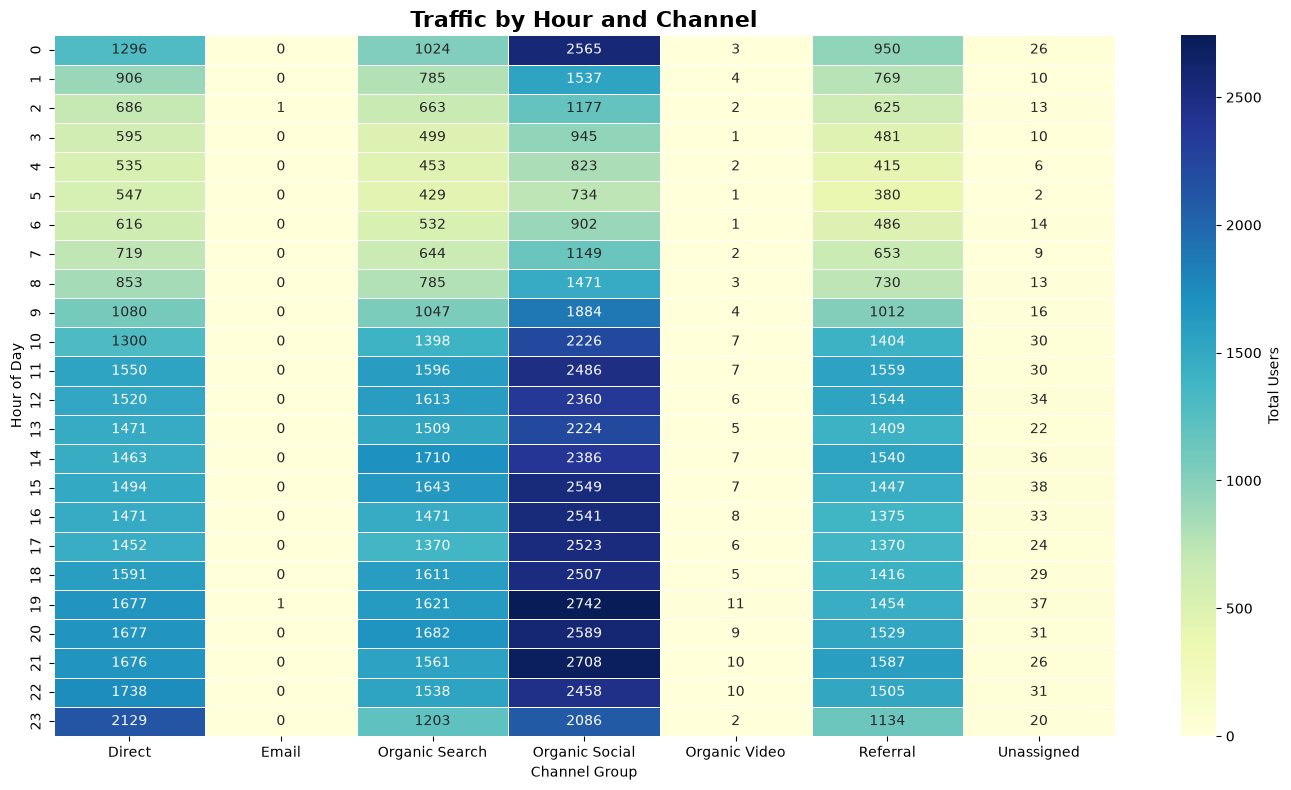

In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Clean column names
df.columns = df.columns.astype(str).str.strip()

# Find columns
date_col = next(
    c for c in df.columns
    if "date" in c.lower() and "hour" in c.lower()
)

channel_col = next(
    c for c in df.columns
    if "channel" in c.lower() and "group" in c.lower()
)

traffic_col = next(
    c for c in df.columns
    if c.lower().strip() == "users"
)

# Extract hour from date-hour column
df["Hour"] = pd.to_numeric(
    df[date_col].astype(str).str.strip().str[-2:],
    errors="coerce"
)

# Convert traffic to numbers
df[traffic_col] = pd.to_numeric(
    df[traffic_col].astype(str).str.replace(",", ""),
    errors="coerce"
)

# Create heatmap data
heatmap_data = df.pivot_table(
    index="Hour",
    columns=channel_col,
    values=traffic_col,
    aggfunc="sum",
    fill_value=0
).sort_index()

# Draw colourful heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Total Users"}
)

plt.title("Traffic by Hour and Channel",
          fontsize=16, fontweight="bold")
plt.xlabel("Channel Group")
plt.ylabel("Hour of Day")
plt.tight_layout()
plt.show()